# 03 — Dataset, EDA & Preprocessing

**Lab 2 — Group 4 | CIFAR-10**

Bước 5: CIFAR-10, khảo sát dữ liệu, chia tập, transforms, DataLoader. EDA là phần bổ sung của nhóm.

Cấu hình được đặt trực tiếp trong cell code đầu tiên của notebook. `review` đọc kết quả lịch sử; `full` chạy mới. Mỗi notebook có thể mở bằng kernel riêng.

In [1]:
from pathlib import Path
import sys, os
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs').is_dir() and (p/'src').is_dir()), None)
assert ROOT is not None, 'Hãy mở notebook trong thư mục dự án đã giải nén.'
sys.path.insert(0, str(ROOT))
# Cấu hình trực tiếp trong notebook (không cần file cấu hình riêng).
MODE = "review"  # review: kết quả gốc; full: chạy thực tế
RUN_ID = "run_01"  # notebook 04–06 phải dùng cùng tên khi chạy full
DEVICE_OVERRIDE = "auto"  # auto / cpu / cuda
CPU_THREADS = 1
LIVE = MODE == "full"
assert MODE in ("review", "full")
DOWNLOAD = True
import io, json, random, hashlib, time, gc
from pathlib import Path
from datetime import datetime
from uuid import uuid4

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])

DATA_DIR = ROOT / 'data'
SESSION_DIR = ROOT / 'outputs' / 'notebook_runs' / RUN_ID
FIG_DIR = SESSION_DIR / 'figures'
SAVE_FIGS = LIVE

def save_fig(name):
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

random.seed(SEED)
np.random.seed(SEED)
if LIVE:
    import torch
    import torchvision
    from torch import nn
    from torch.utils.data import DataLoader, Subset, random_split
    from torchvision import transforms, models
    from PIL import Image
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
    from torch.utils.tensorboard import SummaryWriter
    import torch.nn.functional as F

    def set_seed(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

    set_seed(SEED)
    DEVICE = torch.device(("cuda" if torch.cuda.is_available() else "cpu")
                          if DEVICE_OVERRIDE == "auto" else DEVICE_OVERRIDE)
    if DEVICE.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA không khả dụng. Chọn CPU hoặc sửa môi trường.")
    if DEVICE.type == "cpu":
        torch.set_num_threads(CPU_THREADS)
    print("PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)
    print("Device:", DEVICE)
    print("Data:", DATA_DIR, "| Output mới:", SESSION_DIR)
else:
    print("Review: không cần import PyTorch, không tạo file training.")

Review: không cần import PyTorch, không tạo file training.


## Bước 5. CIFAR-10 — đọc dữ liệu và khám phá (EDA)
Dữ liệu gốc có 50.000 ảnh train và 10.000 ảnh test, ảnh RGB 32×32, 10 lớp. Phân tách train gốc thành 45.000 train và 5.000 validation bằng `random_split` seed 42 (không stratify). Test để đánh giá cuối; thống kê test ở đây chỉ phục vụ mô tả dữ liệu và kiểm tra tính toàn vẹn từng byte như Lab gốc, không tham gia điều chỉnh mô hình.

In [2]:
if LIVE:
    # Dữ liệu thô (uint8, shape [N, 32, 32, 3]) — không qua transform để EDA phản ánh đúng dữ liệu gốc
    train_ds = torchvision.datasets.CIFAR10(root=str(DATA_DIR), train=True, download=DOWNLOAD)
    test_ds = torchvision.datasets.CIFAR10(root=str(DATA_DIR), train=False, download=DOWNLOAD)

    X_train, y_train = train_ds.data, np.array(train_ds.targets)
    X_test, y_test = test_ds.data, np.array(test_ds.targets)
    classes = train_ds.classes
    print("Các lớp:", classes)
else:
    print('Review: sử dụng kết quả đã lưu, không chạy lại bước này.')

Review: sử dụng kết quả đã lưu, không chạy lại bước này.


In [3]:
if not LIVE:
    classes = CLASSES
    overview = pd.DataFrame({"Tập": ["Train gốc", "Test"], "Số ảnh":[50000, 10000],
                             "Shape":["(50000, 32, 32, 3)", "(10000, 32, 32, 3)"],
                             "dtype":["uint8","uint8"], "Min pixel":[0,0], "Max pixel":[255,255]})
else:
    print("Các lớp:", classes)
    overview = pd.DataFrame({"Tập":["Train gốc","Test"], "Số ảnh":[len(X_train),len(X_test)],
                             "Shape":[X_train.shape,X_test.shape], "dtype":[X_train.dtype,X_test.dtype],
                             "Min pixel":[X_train.min(),X_test.min()], "Max pixel":[X_train.max(),X_test.max()]})
display(overview)

,Tập,Số ảnh,Shape,dtype,Min pixel,Max pixel
0,Train gốc,50000,"(50000, 32, 32, 3)",uint8,0,255
1,Test,10000,"(10000, 32, 32, 3)",uint8,0,255


### 5.1. Phân bố lớp, ảnh mẫu và phép chia train/validation

,train,test
airplane,5000,1000
automobile,5000,1000
bird,5000,1000
cat,5000,1000
deer,5000,1000
dog,5000,1000
frog,5000,1000
horse,5000,1000
ship,5000,1000
truck,5000,1000


,train,val,val_share_%
airplane,4512,488,9.76
automobile,4488,512,10.24
bird,4468,532,10.64
cat,4529,471,9.42
deer,4529,471,9.42
dog,4486,514,10.28
frog,4493,507,10.14
horse,4500,500,10.00
ship,4496,504,10.08
truck,4499,501,10.02


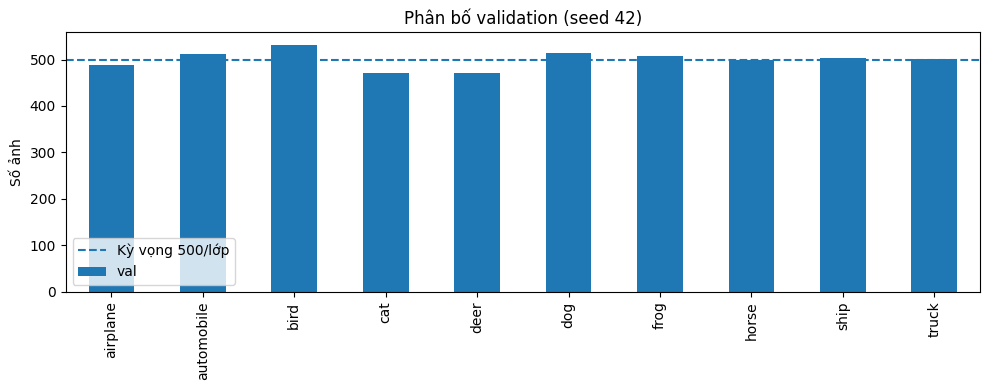

In [4]:
if LIVE:
    dist = pd.DataFrame({"train":np.bincount(y_train,minlength=10),
                         "test":np.bincount(y_test,minlength=10)}, index=classes)
    generator = torch.Generator().manual_seed(SEED)
    train_subset, val_subset = random_split(range(len(X_train)), [45000, 5000], generator=generator)
    train_idx = np.array(train_subset.indices)
    val_idx = np.array(val_subset.indices)
    assert not set(train_idx).intersection(val_idx)
    assert len(train_idx) + len(val_idx) == len(X_train)
    val_counts = np.bincount(y_train[val_idx], minlength=10)
    train_counts = np.bincount(y_train[train_idx], minlength=10)
else:
    dist = pd.DataFrame({"train":[5000]*10, "test":[1000]*10},index=classes)
    val_counts = np.array([488,512,532,471,471,514,507,500,504,501])
    train_counts = 5000 - val_counts
split_dist = pd.DataFrame({"train":train_counts,"val":val_counts},index=classes)
split_dist["val_share_%"] = (100*split_dist["val"]/split_dist["val"].sum()).round(2)
display(dist)
display(split_dist)
ax = split_dist["val"].plot.bar(figsize=(10,4), title="Phân bố validation (seed 42)")
ax.axhline(500, linestyle="--", label="Kỳ vọng 500/lớp")
ax.set_ylabel("Số ảnh")
ax.legend()
plt.tight_layout()
save_fig("validation_distribution.png")
plt.show()

In [5]:
if LIVE:
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(10, 8, figsize=(10, 12.5))
    for c in range(10):
        chosen = rng.choice(np.where(y_train == c)[0], 8, replace=False)
        for j, i in enumerate(chosen):
            axes[c, j].imshow(X_train[i])
            axes[c, j].axis("off")
            if j == 0:
                axes[c, j].set_title(classes[c], loc="left", fontsize=9)
    plt.tight_layout()
    save_fig("eda_samples_per_class.png")
    plt.show()
else:
    print('Review: sử dụng kết quả đã lưu, không chạy lại bước này.')

Review: sử dụng kết quả đã lưu, không chạy lại bước này.


**Ảnh mẫu CIFAR-10 — hình lưu từ Lab 2 gốc (không phải lần chạy mới).**

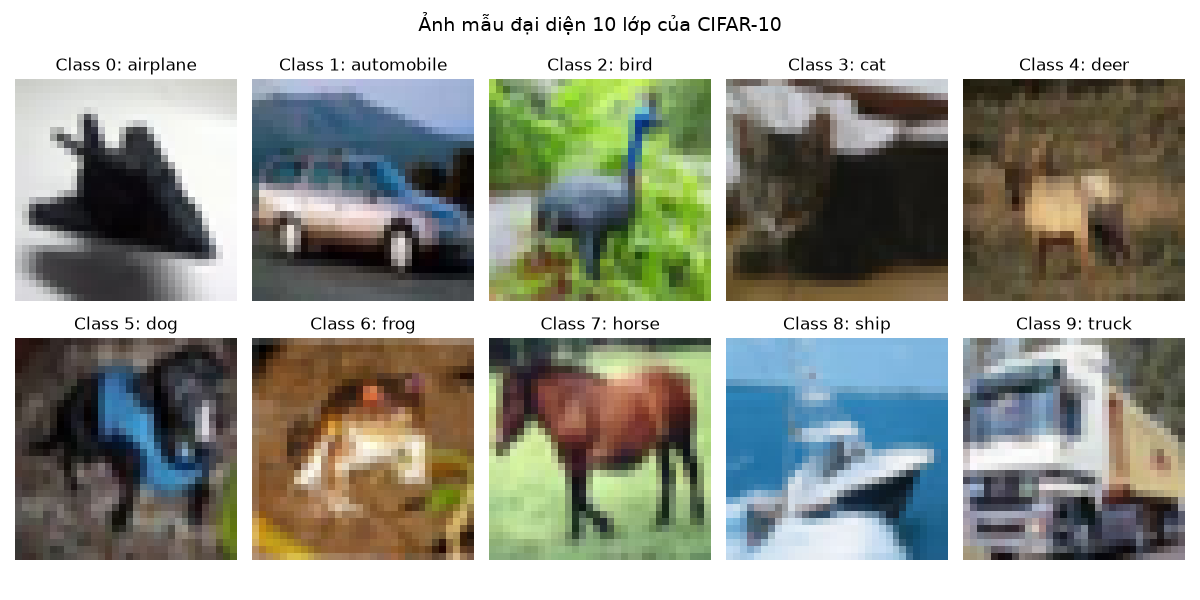

### 5.2. Thống kê pixel, độ sáng và kiểm tra trùng lặp
Mean/std được tính trong thang [0,1]. Dùng chuẩn ImageNet khi đưa ảnh vào model pretrained, thay vì lấy mean/std của CIFAR-10.

In [6]:
if LIVE:
    def channel_stats(X, chunk=5000):
        """Mean/std theo kênh RGB trong thang [0, 1], tính theo từng khối để tiết kiệm RAM."""
        n, s, s2 = 0, np.zeros(3), np.zeros(3)
        for i in range(0, len(X), chunk):
            b = X[i:i + chunk].astype(np.float64) / 255.0
            s += b.sum(axis=(0, 1, 2))
            s2 += (b ** 2).sum(axis=(0, 1, 2))
            n += b.shape[0] * b.shape[1] * b.shape[2]
        mean = s / n
        return mean, np.sqrt(s2 / n - mean ** 2)

    train_mean, train_std = channel_stats(X_train)
    test_mean, test_std = channel_stats(X_test)

    stats = pd.DataFrame({
        "CIFAR train mean": train_mean, "CIFAR test mean": test_mean, "ImageNet mean": IMAGENET_MEAN,
        "CIFAR train std": train_std, "CIFAR test std": test_std, "ImageNet std": IMAGENET_STD,
    }, index=["R", "G", "B"]).round(4)
else:
    stats = pd.DataFrame({
        "CIFAR train mean":[.4914,.4822,.4465],
        "CIFAR test mean":[.4942,.4851,.4504],
        "ImageNet mean":IMAGENET_MEAN,
        "CIFAR train std":[.2470,.2435,.2616],
        "CIFAR test std":[.2467,.2429,.2616],
        "ImageNet std":IMAGENET_STD},index=["R","G","B"])
display(stats)

,CIFAR train mean,CIFAR test mean,ImageNet mean,CIFAR train std,CIFAR test std,ImageNet std
R,0.4914,0.4942,0.485,0.2470,0.2467,0.229
G,0.4822,0.4851,0.456,0.2435,0.2429,0.224
B,0.4465,0.4504,0.406,0.2616,0.2616,0.225


In [7]:
if LIVE:
    # Histogram cường độ pixel theo kênh (tính chính xác trên toàn bộ tập train)
    fig, ax = plt.subplots(figsize=(9, 4))
    for c, (color, name) in enumerate(zip(["red", "green", "blue"], ["R", "G", "B"])):
        counts = np.bincount(X_train[..., c].ravel(), minlength=256)
        ax.plot(counts / counts.sum(), color=color, label=name)
    ax.set_xlabel("Giá trị pixel (0–255)")
    ax.set_ylabel("Tỉ lệ pixel")
    ax.set_title("Phân bố cường độ pixel theo kênh (train)")
    ax.legend()
    plt.tight_layout()
    save_fig("eda_pixel_histogram.png")
    plt.show()
else:
    print('Review: sử dụng kết quả đã lưu, không chạy lại bước này.')

Review: sử dụng kết quả đã lưu, không chạy lại bước này.


In [8]:
if LIVE:
    rgb_mean = X_train.mean(axis=(1, 2))                       # [N, 3]
    brightness = rgb_mean @ np.array([0.299, 0.587, 0.114])   # độ sáng (luma) mỗi ảnh

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].boxplot([brightness[y_train == c] for c in range(10)])
    axes[0].set_xticks(range(1, 11))
    axes[0].set_xticklabels(classes, rotation=45)
    axes[0].set_ylabel("Độ sáng trung bình (0–255)")
    axes[0].set_title("Phân bố độ sáng theo lớp")

    # Ảnh trung bình của từng lớp
    mean_imgs = np.stack([X_train[y_train == c].mean(axis=0) / 255.0 for c in range(10)])
    canvas = np.concatenate([np.concatenate(list(mean_imgs[:5]), axis=1),
                             np.concatenate(list(mean_imgs[5:]), axis=1)], axis=0)
    axes[1].imshow(np.clip(canvas, 0, 1))
    axes[1].set_xticks([16 + 32 * i for i in range(5)])
    axes[1].set_xticklabels(classes[:5], fontsize=8)
    axes[1].set_yticks([16, 48])
    axes[1].set_yticklabels(["lớp 0–4", "lớp 5–9"], fontsize=8)
    axes[1].set_title("Ảnh trung bình mỗi lớp")
    axes[1].grid(False)
    plt.tight_layout()
    save_fig("eda_brightness_mean_images.png")
    plt.show()

    per_class_rgb = pd.DataFrame(rgb_mean, columns=["R", "G", "B"])
    per_class_rgb["lớp"] = [classes[i] for i in y_train]
    display(per_class_rgb.groupby("lớp").mean().round(2))
else:
    print('Review: sử dụng kết quả đã lưu, không chạy lại bước này.')

Review: sử dụng kết quả đã lưu, không chạy lại bước này.


In [9]:
if LIVE:
    def image_hashes(X):
        return [hashlib.md5(img.tobytes()).hexdigest() for img in X]

    h_train, h_test = image_hashes(X_train), image_hashes(X_test)
    print(f"Ảnh trùng lặp bên trong train: {len(h_train) - len(set(h_train))}")
    print(f"Ảnh trùng lặp bên trong test : {len(h_test) - len(set(h_test))}")
    print(f"Ảnh xuất hiện ở cả train và test: {len(set(h_train) & set(h_test))}")
else:
    print("Theo output gốc: trùng byte trong train = 0; trong test = 0; giao train/test = 0.")

Theo output gốc: trùng byte trong train = 0; trong test = 0; giao train/test = 0.


**Histogram pixel và độ sáng theo lớp — hình lưu từ Lab 2 gốc (không phải lần chạy mới).**

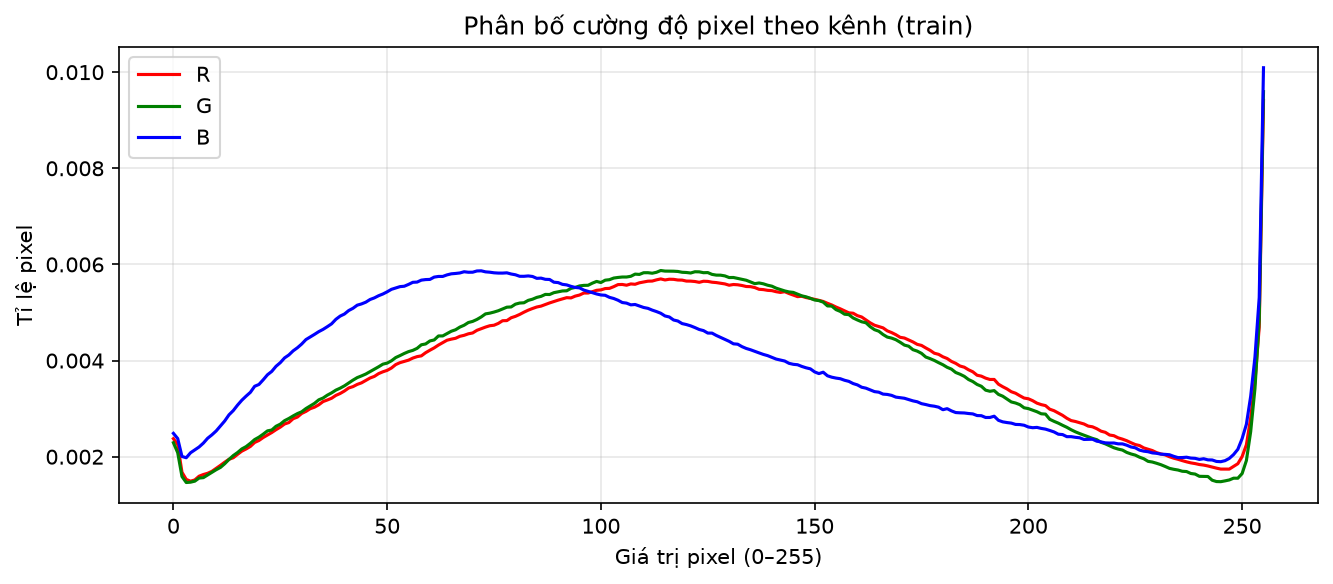

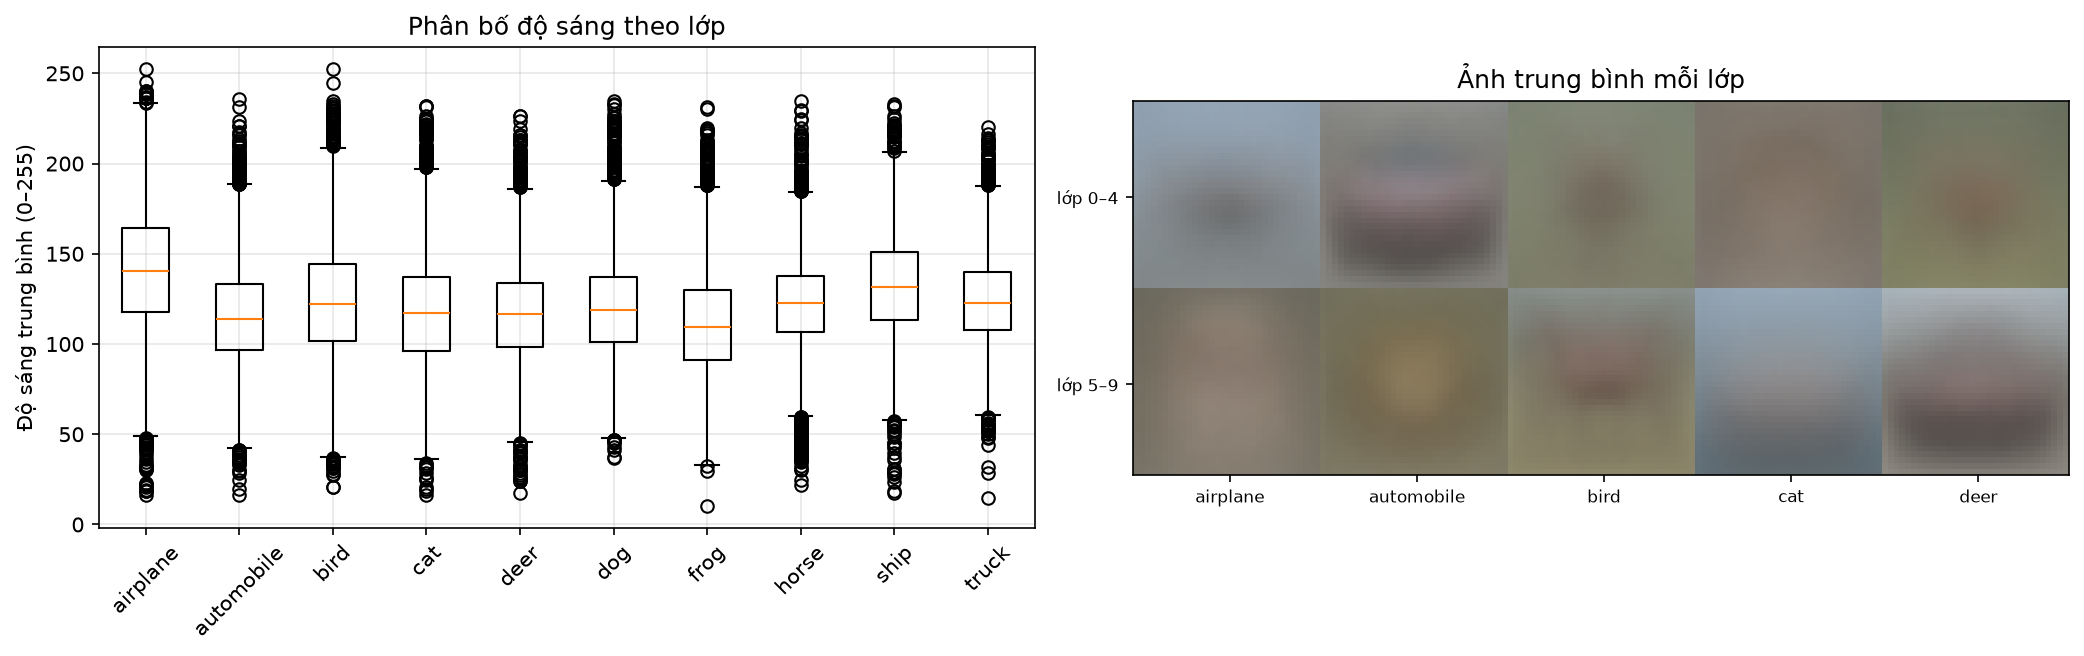

### 5.3. Tác động của resize
Resize 32×32 lên 224×224 làm số pixel tăng 49 lần (12 KiB → 588 KiB cho tensor float32 3 kênh). Resize không tạo thêm chi tiết thật; nó phù hợp với thiết lập input của Lab và làm tăng chi phí tính toán.

In [10]:
if LIVE:
    from PIL import Image
    from torchvision import transforms

    i = 0
    orig = Image.fromarray(X_train[i])
    resized = transforms.Resize((224, 224))(orig)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(orig); axes[0].set_title("Gốc 32×32"); axes[0].axis("off")
    axes[1].imshow(resized); axes[1].set_title("Sau Resize 224×224"); axes[1].axis("off")
    plt.tight_layout()
    save_fig("eda_resize_effect.png")
    plt.show()

    ratio = (224 * 224) / (32 * 32)
    print(f"Số pixel tăng {ratio:.0f} lần")
    print(f"Bộ nhớ 1 ảnh float32: {3 * 32 * 32 * 4 / 1024:.1f} KB (32×32) -> {3 * 224 * 224 * 4 / 1024:.1f} KB (224×224)")
else:
    print('Review: sử dụng kết quả đã lưu, không chạy lại bước này.')

Review: sử dụng kết quả đã lưu, không chạy lại bước này.


**Minh họa resize — hình lưu từ Lab 2 gốc (không phải lần chạy mới).**

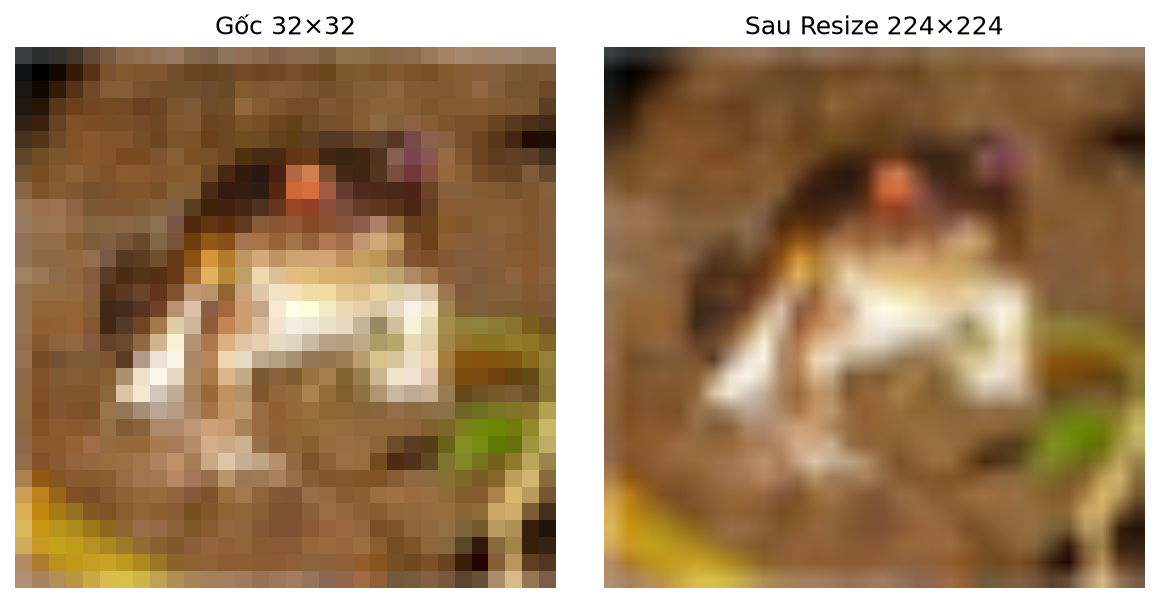

**Nhận xét EDA:** dữ liệu gốc cân bằng 5.000 ảnh/lớp ở train và 1.000 ảnh/lớp ở test. Validation dao động 471–532 ảnh/lớp. Không phát hiện trùng byte trong kiểm tra lưu trước đó, nhưng điều này không chứng minh loại trừ mọi dạng data leakage (ví dụ ảnh gần giống).

## Preprocessing — DataLoader
Dùng module `src/data.py`; resize 224×224, augmentation chỉ trên train, normalize theo ImageNet, seed 42, train/val/test = 45.000/5.000/10.000.

In [11]:
if LIVE:
    from src.data import get_transforms, build_dataloaders
    config = dict(data_dir=str(DATA_DIR), batch_size=32, seed=SEED, image_size=224, val_ratio=.1, num_workers=0)
    train_tf, eval_tf = get_transforms(224)
    print('Train transforms:', train_tf, '\nEval transforms:',eval_tf)
    loaders = build_dataloaders(config)
    print({k:len(loaders[k].dataset) for k in ('train','val','test')})
    images, labels = next(iter(loaders['train']))
    print(images.shape, labels.shape, labels.dtype)
    assert images.shape[1:] == (3,224,224) and labels.dtype == torch.long
else:
    display(pd.DataFrame({'Split':['Train','Validation','Test'],'Số ảnh':[45000,5000,10000]}))
    print('Thông số cấu hình gốc: batch=32, image_size=224, seed=42.')

,Split,Số ảnh
0,Train,45000
1,Validation,5000
2,Test,10000


Thông số cấu hình gốc: batch=32, image_size=224, seed=42.
